# Julia から Wolfram Engine を呼び出す — 整数を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します。

整数の計算は Julia だけでもかなりできます（`gcd`, `powermod`, `Primes.jl` など）。  
ここでは Julia と Wolfram を並べて使い，**Wolfram が得意なこと**（不定方程式の整数解，合同式，連分数など）の結果を Julia で確かめます。

- 素因数分解・約数・最大公約数
- 1 次不定方程式 $ax + by = c$ の整数解 → 解を **Julia の関数**にする
- いろいろな不定方程式の整数解 → **Julia の配列**にする
- 合同式・中国剰余定理・$n$ 進法
- 循環小数・連分数
- 素数の分布

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数は `wolfram_common.jl` にまとめてあります（このノートブックと同じフォルダに置きます）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Primes", "Plots"])

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数
using Primes                      # Julia の素数関連（factor, isprime, primes など）
using Plots

## 1. 基本：Wolfram と Julia の整数

| | Wolfram | Julia |
|---|---|---|
| 素因数分解 | `FactorInteger[n]` | `factor(n)`（Primes.jl） |
| 最大公約数・最小公倍数 | `GCD[a, b]`, `LCM[a, b]` | `gcd(a, b)`, `lcm(a, b)` |
| 余り | `Mod[a, m]` | `mod(a, m)` |
| 累乗の余り | `PowerMod[a, n, m]` | `powermod(a, n, m)` |
| 素数判定 | `PrimeQ[n]` | `isprime(n)` |

Wolfram の整数は桁数に制限がありません。Julia の `Int` は 64 ビット（約 $9.2 \times 10^{18}$ まで）なので，大きな数は `big` を使います。

In [3]:
weval(W`FactorInteger[360]`)                 # {素因数, 指数} のリスト

W`List[List[2, 3], List[3, 2], List[5, 1]]`

In [4]:
factor(360)                                  # Julia（Primes.jl）

2^3 * 3^2 * 5

In [5]:
w = weval(W`2^100`)                          # Wolfram の大きな整数
to_value(w), typeof(to_value(w)), big(2)^100, 2^100      # Julia では BigInt になる。Int のままの 2^100 は桁あふれして 0

(1267650600228229401496703205376, BigInt, 1267650600228229401496703205376, 0)

## 2. このノートブックで使う関数

In [6]:
# 「左辺 = 結果」を表示して，結果（Wolfram の式）を返す。lhs で左辺の LaTeX を指定できる
function calc(cmd::AbstractString; lhs=nothing)
    res = weval(wparse(cmd))
    showtex((lhs === nothing ? heldtex(cmd) : lhs) * " = " * tex(res))
    return res
end

# 素因数分解を 2^3 · 3^2 · 5 の形で表示して，[素因数, 指数] の配列を返す
function factorize(n)
    fw = weval(wparse("FactorInteger[$n]"))
    showtex((n isa AbstractString ? heldtex(n) : string(n)) * " = " * join((tex(f.args[1]) * (f.args[2] == 1 ? "" : "^{$(f.args[2])}") for f in fw.args), " \\cdot "))
    return to_value(fw)
end

factorize (generic function with 1 method)

In [7]:
fs = factorize(360)
factorize(2026)
factorize(1001)
factorize("2^32 + 1")                        # フェルマー数 F5（オイラーが分解した）
factorize("2^67 - 1");                       # メルセンヌ数（1903 年にコールが分解した）

fs, prod(p^e for (p, e) in fs)               # Julia の配列として受け取り，掛け戻して確かめる

([[2, 3], [3, 2], [5, 1]], 360)

## 3. 約数と最大公約数

### 約数の個数と総和

$n = p^a q^b \cdots$ のとき，約数の個数は $(a+1)(b+1)\cdots$，総和は $(1 + p + \dots + p^a)(1 + q + \dots + q^b)\cdots$ です。

In [8]:
dw = calc("Divisors[360]"; lhs="360 \\text{ の約数}")
calc("DivisorSigma[0, 360]"; lhs="\\text{個数}")
calc("DivisorSigma[1, 360]"; lhs="\\text{総和}")

d = to_value(dw)
length(d), sum(d), prod(e + 1 for (p, e) in fs), prod(sum(p^k for k in 0:e) for (p, e) in fs)      # 公式で検算

(24, 1170, 24, 1170)

In [9]:
# 完全数（自分自身を除く約数の和が自分に等しい数）を 10000 以下で探す
pw_ = calc("Select[Range[10000], DivisorSigma[1, #] == 2 # &]"; lhs="\\text{10000 以下の完全数}")
[(m, sum(k for k in 1:m-1 if m % k == 0)) for m in to_value(pw_)]         # Julia で約数の和を確かめる

4-element Vector{Tuple{Int64, Int64}}:
 (6, 6)
 (28, 28)
 (496, 496)
 (8128, 8128)

### ユークリッドの互除法

`ExtendedGCD[a, b]` は $\gcd(a, b)$ と，$as + bt = \gcd(a, b)$ を満たす整数 $s, t$ を返します。Julia では `gcdx` です。

In [10]:
gw = calc("ExtendedGCD[391, 221]"; lhs="\\{\\gcd, \\{s, t\\}\\}")
g, (s, t) = to_value(gw)
g, 391s + 221t, gcdx(391, 221)

(17, 17, (17, 4, -7))

In [11]:
# 互除法の途中経過を Julia で表示する
function euclid(a, b)
    while b != 0
        println("$a = $b × $(a ÷ b) + $(a % b)")
        a, b = b, a % b
    end
    return a
end
euclid(391, 221)

391 = 221 × 1 + 170
221 = 170 × 1 + 51
170 = 51 × 3 + 17
51 = 17 × 3 + 0


17

## 4. 1 次不定方程式 $ax + by = c$

`isolve(方程式, 変数...)` は，方程式の**整数解**を求めます。

- 解が無数にあるとき：整数 $k$ を使った一般解を表示し，`(Wolfram の式, k -> (x = .., y = ..) という Julia の関数)` を返す
- 解が有限個のとき：すべての解を表示し，`(Wolfram の式, 解の配列)` を返す

In [12]:
function isolve(eq::AbstractString, vars::AbstractString...)
    vs = join(vars, ", ")
    # 整数の範囲で解く。一般解は「C[1] が整数ならば…」という条件つきで返るので，条件を外す
    res = weval(wparse("Solve[$eq, {$vs}, Integers] /. ConditionalExpression[e_, _] :> e"))
    islist(res) || error("Solve では整数解を求められませんでした。")
    lhs = length(vars) == 1 ? vs : "($vs)"
    eqt = replace(heldtex(eq), "\\land" => ",\\ \\ ")              # 条件の「かつ」はカンマで表示
    one(sol) = (v = [tex(r.args[2]) for r in sol.args]; length(v) == 1 ? v[1] : "\\left(" * join(v, ",\\ ") * "\\right)")
    if isempty(res.args)
        showtex(eqt * "\\iff \\text{整数解なし}")
        return res, []
    elseif occursin("C[", string(res))                       # 一般解（任意の整数 C[1] を含む）
        sol = res.args[1]
        showtex(eqt * "\\iff " * lhs * " = " * replace(one(sol), r"c_1" => "k") * "\\quad (k \\text{ は整数})")
        return sol, to_function(sol, :C1)
    else
        showtex(eqt * "\\iff " * lhs * " = " * join(one.(res.args), ",\\ \\ "))
        return res, to_value(res)
    end
end

isolve (generic function with 1 method)

In [13]:
_, sol = isolve("3 x + 5 y == 1", "x", "y")
[sol(k) for k in -2:2]                        # k = -2, ..., 2 のときの解

5-element Vector{@NamedTuple{x::Int64, y::Int64}}:
 (x = -8, y = 5)
 (x = -3, y = 2)
 (x = 2, y = -1)
 (x = 7, y = -4)
 (x = 12, y = -7)

In [14]:
all(3 * sol(k).x + 5 * sol(k).y == 1 for k in -100:100)       # 検算

true

In [15]:
isolve("391 x + 221 y == 17", "x", "y")
isolve("391 x + 221 y == 18", "x", "y")      # 右辺が gcd(391, 221) = 17 の倍数でないと解なし
isolve("7 x - 4 y == 3", "x", "y")
isolve("2 x + 3 y + 5 z == 1 && z == 1", "x", "y", "z");

**解を格子点として描く**：$3x + 5y = 1$ の整数解は，直線上の格子点です。

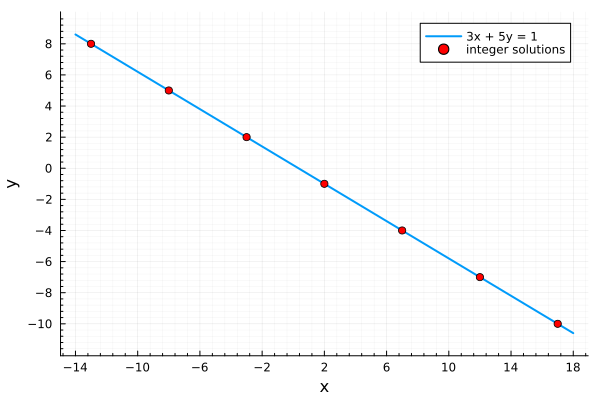

In [16]:
pts = [sol(k) for k in -3:3]
plot(x -> (1 - 3x) / 5, -14, 18; label="3x + 5y = 1", lw=2, xlabel="x", ylabel="y", aspect_ratio=1,
     xticks=-14:4:18, yticks=-10:2:8, minorgrid=true)
scatter!([p.x for p in pts], [p.y for p in pts]; color=:red, label="integer solutions")

## 5. いろいろな不定方程式

条件（正の整数，範囲など）は `&&` でつなぎます。解が有限個なら，NamedTuple の配列になります。

In [17]:
_, s1 = isolve("x y - 2 x - 3 y == 0", "x", "y")                    # (x - 3)(y - 2) = 6 と変形できる
_, s2 = isolve("1/x + 1/y == 1/2 && x > 0 && y > 0", "x", "y")
_, s3 = isolve("x^2 - y^2 == 15 && x > 0 && y > 0", "x", "y")
_, s4 = isolve("x + 2 y + 3 z == 10 && x > 0 && y > 0 && z > 0", "x", "y", "z")
_, s5 = isolve("x^2 + y^2 == 25", "x", "y")
_, s6 = isolve("x^2 + y^2 == 3", "x", "y");

In [18]:
s1

8-element Vector{@NamedTuple{x::Int64, y::Int64}}:
 (x = -3, y = 1)
 (x = 0, y = 0)
 (x = 1, y = -1)
 (x = 2, y = -4)
 (x = 4, y = 8)
 (x = 5, y = 5)
 (x = 6, y = 4)
 (x = 9, y = 3)

In [19]:
# Julia でしらみつぶしに探した結果と比べる
brute = [(x = x, y = y) for x in -50:50 for y in -50:50 if x * y - 2x - 3y == 0]
Set(s1) == Set(brute), length(s1)

(true, 8)

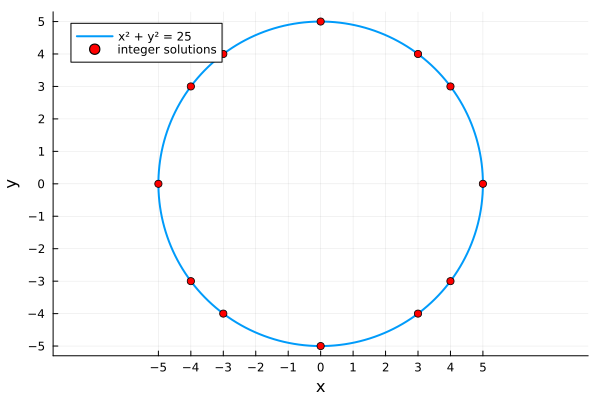

In [20]:
# x² + y² = 25 の整数解を円の上に描く
t = range(0, 2π; length=200)
plot(5cos.(t), 5sin.(t); aspect_ratio=1, label="x² + y² = 25", lw=2, xticks=-5:5, yticks=-5:5, xlabel="x", ylabel="y")
scatter!([p.x for p in s5], [p.y for p in s5]; color=:red, label="integer solutions")

### ピタゴラス数

$a^2 + b^2 = c^2$ を満たす自然数の組。$c \le 30$ の範囲で探します。

In [21]:
_, py = isolve("a^2 + b^2 == c^2 && 0 < a < b < c <= 30", "a", "b", "c")
[p for p in py if gcd(p.a, p.b, p.c) == 1]                   # 互いに素なもの（原始ピタゴラス数）だけ Julia で選ぶ

5-element Vector{@NamedTuple{a::Int64, b::Int64, c::Int64}}:
 (a = 3, b = 4, c = 5)
 (a = 5, b = 12, c = 13)
 (a = 7, b = 24, c = 25)
 (a = 8, b = 15, c = 17)
 (a = 20, b = 21, c = 29)

## 6. 合同式

$a \equiv b \pmod m$：$a$ と $b$ を $m$ で割った余りが等しい。

In [22]:
calc("Mod[2026, 7]"; lhs="2026 \\bmod 7")
calc("PowerMod[3, 100, 7]"; lhs="3^{100} \\bmod 7")
calc("PowerMod[7, 2026, 100]"; lhs="7^{2026} \\text{ の下 2 桁}")
iw = calc("PowerMod[3, -1, 7]"; lhs="3^{-1} \\bmod 7")              # 3x ≡ 1 (mod 7) の解

mod(2026, 7), powermod(3, 100, 7), powermod(7, 2026, 100), invmod(3, 7)      # Julia の関数

(3, 4, 49, 5)

In [23]:
# 余りの周期：3^n を 7 で割った余り
[powermod(3, n, 7) for n in 0:12]

13-element Vector{Int64}:
 1
 3
 2
 6
 4
 5
 1
 3
 2
 6
 4
 5
 1

### 合同方程式と中国剰余定理

「3 で割ると 2 余り，5 で割ると 3 余り，7 で割ると 2 余る数」を求めます。

In [24]:
calc("x /. First[Solve[3 x == 1, x, Modulus -> 7]]"; lhs="3x \\equiv 1 \\pmod 7 \\iff x")
calc("x /. Solve[x^2 == 2, x, Modulus -> 7]"; lhs="x^2 \\equiv 2 \\pmod 7 \\text{ の解 } x")
cw = calc("ChineseRemainder[{2, 3, 2}, {3, 5, 7}]"; lhs="x")
_, crt = isolve("Mod[x, 3] == 2 && Mod[x, 5] == 3 && Mod[x, 7] == 2", "x")

x0 = to_value(cw)
x0, [x for x in 1:300 if x % 3 == 2 && x % 5 == 3 && x % 7 == 2], [crt(k).x for k in 0:2]     # Julia でしらみつぶし

(23, [23, 128, 233], [23, 128, 233])

### オイラーの関数とフェルマーの小定理

$\varphi(n)$ は $1, \dots, n$ のうち $n$ と互いに素なものの個数です。$p$ が素数で $a$ が $p$ の倍数でなければ $a^{p-1} \equiv 1 \pmod p$。

In [25]:
calc("EulerPhi[360]"; lhs="\\varphi(360)")
calc("Table[PowerMod[a, 12, 13], {a, 1, 12}]"; lhs="a^{12} \\bmod 13\\ (a = 1, \\dots, 12)")
count(k -> gcd(k, 360) == 1, 1:360)                          # Julia で数える

96

## 7. $n$ 進法

In [26]:
bw = calc("IntegerDigits[2026, 2]"; lhs="2026 \\text{ の 2 進法の各位}")
calc("IntegerDigits[2026, 5]"; lhs="2026 \\text{ の 5 進法の各位}")
calc("FromDigits[{1, 0, 1, 1, 0, 1}, 2]"; lhs="101101_{(2)}")
calc("FromDigits[{2, 1, 0, 2}, 3]"; lhs="2102_{(3)}")

# Julia では digits（下の位から），string，parse
to_value(bw), reverse(digits(2026; base=2)), string(2026; base=2), parse(Int, "101101"; base=2)

([1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0], [1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0], "11111101010", 45)

## 8. 循環小数と連分数

### 循環小数

`RealDigits[分数]` は，循環しない部分と循環節（内側のリスト）を返します。  
$\frac{1}{p}$ の循環節の長さは，$10^k \equiv 1 \pmod p$ となる最小の $k$（`MultiplicativeOrder[10, p]`）です。

In [27]:
# 循環小数を 0.\dot{1}4285\dot{7} の形で表示する（循環節を {} で示す）
function repeating(q::AbstractString; base=10)
    rw = weval(wparse("RealDigits[$q, $base]"))
    digs, ex = rw.args[1].args, rw.args[2]
    head = [d for d in digs if d isa Integer]                 # 循環しない部分
    rep  = [d for d in digs if !(d isa Integer)]              # 循環節（リスト）
    cyc  = isempty(rep) ? Int[] : collect(rep[1].args)
    all_digits = vcat(zeros(Int, max(0, -ex)), head)          # 小数点以下の先頭の 0 を補う
    ip = ex > 0 ? join(all_digits[1:ex]) : "0"
    fp = ex > 0 ? join(all_digits[ex+1:end]) : join(all_digits)
    showtex(heldtex(q) * " = " * ip * "." * fp * (isempty(cyc) ? "" : "\\{" * join(cyc) * "\\}") *
            (base == 10 ? "" : "_{($base)}") *
            (isempty(cyc) ? "" : "\\quad (\\text{循環節の長さ } $(length(cyc)))"))
    return cyc
end

repeating("1/7")
repeating("1/6")
repeating("22/7")
repeating("1/13")
repeating("3/8")
repeating("1/17");

**2 進法の循環小数**：10 進法では有限小数の $0.1$ も，2 進法では循環小数になります。コンピュータの小数（2 進法）で `0.1 + 0.2 == 0.3` が成り立たないのはこのためです。

In [28]:
repeating("1/10"; base=2)
repeating("1/5"; base=2)
repeating("3/8"; base=2)
0.1 + 0.2 == 0.3, 1 // 10 + 2 // 10 == 3 // 10               # 小数では誤差が出るが，分数なら厳密

(false, true)

In [29]:
# 1/p の循環節の長さ：Wolfram の MultiplicativeOrder と，Julia で 10^k mod p を調べた結果
function period(p)
    k, r = 1, 10 % p
    while r != 1
        r = r * 10 % p; k += 1
    end
    return k
end

ps = [7, 11, 13, 17, 19, 23, 29, 31, 37, 41]
ow = to_value(weval(wparse("MultiplicativeOrder[10, #] & /@ {$(join(ps, ", "))}")))
[(p, o, period(p)) for (p, o) in zip(ps, ow)]

10-element Vector{Tuple{Int64, Int64, Int64}}:
 (7, 6, 6)
 (11, 2, 2)
 (13, 6, 6)
 (17, 16, 16)
 (19, 18, 18)
 (23, 22, 22)
 (29, 28, 28)
 (31, 15, 15)
 (37, 3, 3)
 (41, 5, 5)

### 連分数

$\sqrt2 = 1 + \cfrac{1}{2 + \cfrac{1}{2 + \cfrac{1}{2 + \cdots}}}$ のように，無理数を分数の入れ子で表します。途中で打ち切ると，よい近似分数が得られます。

In [30]:
calc("ContinuedFraction[Sqrt[2], 10]"; lhs="\\sqrt{2} \\text{ の連分数展開}")
cvw = calc("Convergents[Sqrt[2], 10]"; lhs="\\text{近似分数}")
calc("ContinuedFraction[Pi, 6]"; lhs="\\pi \\text{ の連分数展開}")
piw = calc("Convergents[Pi, 5]"; lhs="\\text{近似分数}")

cv = to_value(cvw)                           # Julia の分数（Rational）の配列
[(c, Float64(c), abs(Float64(c) - sqrt(2))) for c in cv[1:6]]

6-element Vector{Tuple{Rational{Int64}, Float64, Float64}}:
 (1, 1.0, 0.41421356237309515)
 (3//2, 1.5, 0.08578643762690485)
 (7//5, 1.4, 0.014213562373095234)
 (17//12, 1.4166666666666667, 0.002453104293571595)
 (41//29, 1.4137931034482758, 0.00042045892481934466)
 (99//70, 1.4142857142857144, 7.215191261922271e-5)

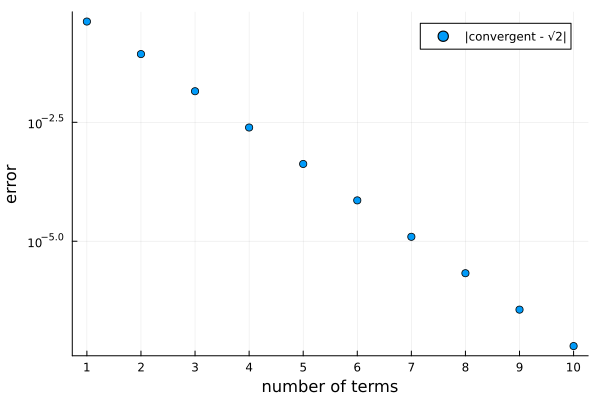

In [31]:
scatter(1:10, [abs(Float64(c) - sqrt(big(2))) for c in cv]; yscale=:log10, label="|convergent - √2|",
        xlabel="number of terms", ylabel="error", legend=:topright, xticks=1:10)

In [32]:
# π の近似分数：22/7 と 355/113 が現れる
[(c, Float64(c) - π) for c in to_value(piw)]

5-element Vector{Tuple{Rational{Int64}, Float64}}:
 (3, -0.14159265358979312)
 (22//7, 0.0012644892673496777)
 (333//106, -8.32196275291075e-5)
 (355//113, 2.667641894049666e-7)
 (103993//33102, -5.778906242426274e-10)

## 9. 素数

### 素数を求める・判定する

In [33]:
calc("Prime[100]"; lhs="100 \\text{ 番目の素数}")
calc("PrimePi[1000]"; lhs="1000 \\text{ 以下の素数の個数}")
calc("NextPrime[10^12]"; lhs="10^{12} \\text{ より大きい最小の素数}")
calc("PrimeQ[2^61 - 1]"; lhs="2^{61} - 1 \\text{ は素数か}")

prime(100), length(primes(1000)), nextprime(10^12 + 1), isprime(2^61 - 1)       # Julia（Primes.jl）

(541, 168, 1000000000039, true)

### 素数の分布

$x$ 以下の素数の個数 $\pi(x)$ は，$\dfrac{x}{\log x}$ や対数積分 $\mathrm{li}(x) = \displaystyle\int_0^x \frac{dt}{\log t}$ で近似できます（素数定理）。  
$\pi(x)$ は Julia で数え，$\mathrm{li}(x)$ は Wolfram で計算して比べます。

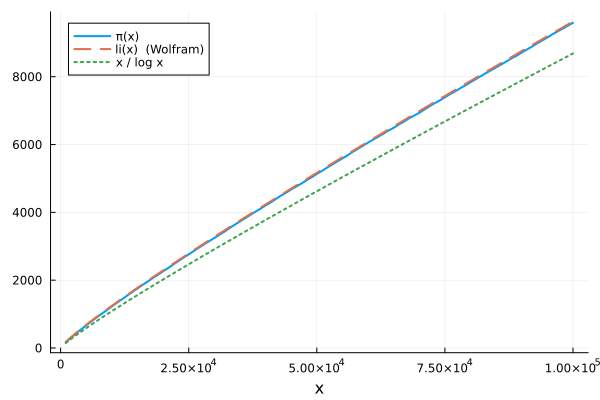

In [34]:
xs = 1000:1000:100_000
liw = weval(wparse("Table[N[LogIntegral[x]], {x, 1000, 100000, 1000}]"))
li = to_value(liw)                           # Wolfram で計算した li(x) の値（Julia の配列）

ps_all = primes(100_000)
πx = [searchsortedlast(ps_all, x) for x in xs]              # x 以下の素数の個数（Julia）

plot(xs, πx; lw=2, label="π(x)", xlabel="x", legend=:topleft)
plot!(xs, li; ls=:dash, lw=2, label="li(x)  (Wolfram)")
plot!(xs, xs ./ log.(xs); ls=:dot, lw=2, label="x / log x")

In [35]:
[(x, p, round(l; digits=1), round(x / log(x); digits=1)) for (x, p, l) in zip(xs[[1, 10, 50, 100]], πx[[1, 10, 50, 100]], li[[1, 10, 50, 100]])]

4-element Vector{Tuple{Int64, Int64, Float64, Float64}}:
 (1000, 168, 177.6, 144.8)
 (10000, 1229, 1246.1, 1085.7)
 (50000, 5133, 5166.5, 4621.2)
 (100000, 9592, 9629.8, 8685.9)

### 2 つの整数が互いに素である確率

でたらめに選んだ 2 つの自然数が互いに素である確率は $\dfrac{1}{\zeta(2)} = \dfrac{6}{\pi^2}$ です。Wolfram の厳密値と，Julia の乱数実験を比べます。

In [36]:
zw = calc("1/Zeta[2]"; lhs="\\frac{1}{\\zeta(2)}")

N = 1_000_000
hits = count(_ -> gcd(rand(1:10^9), rand(1:10^9)) == 1, 1:N)
to_value(zw), hits / N

(0.6079271018540268, 0.608578)

## 10. 大きな数

Wolfram の整数は何桁でも厳密です。Julia でも `big` を付ければ同じ計算ができます。

In [37]:
fw = weval(W`100!`)
f100 = to_value(fw)                          # BigInt として受け取る
f100 == factorial(big(100)), length(string(f100))            # Julia の計算と一致，桁数

(true, 158)

In [38]:
# 100! の末尾に並ぶ 0 の個数 = 100! を割り切る 10 の最高べき
calc("IntegerExponent[100!, 10]"; lhs="100! \\text{ の末尾の 0 の個数}")
sum(100 ÷ 5^k for k in 1:3)                  # 5 の倍数，25 の倍数，125 の倍数の個数の和

24

## 11. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **Julia で桁あふれする**：`2^100` は `Int` では 0 になります（エラーにならないので注意）。`big(2)^100` と書きます。
- **整数解が無数にあって複雑**：2 次以上の不定方程式（ペル方程式など）の一般解は，Julia の関数にしにくい形で返ります。`&& 0 < x < 100` のように範囲を付けて有限個にします。
- **等号は `==`**：合同式は `Mod[x, 3] == 2` のように書きます。
- **時間がかかる**：大きな数の素因数分解は，桁数が増えると急に難しくなります（それが暗号の安全性の根拠です）。

In [39]:
# ペル方程式 x² - 2y² = 1：範囲を付けて解を求める
_, pell = isolve("x^2 - 2 y^2 == 1 && 0 < x < 10^6 && y > 0", "x", "y")
[(p.x, p.y, p.x // p.y, Float64(p.x / p.y)) for p in pell]   # x/y は √2 の近似分数（連分数の近似分数と同じもの）

8-element Vector{Tuple{Int64, Int64, Rational{Int64}, Float64}}:
 (3, 2, 3//2, 1.5)
 (17, 12, 17//12, 1.4166666666666667)
 (99, 70, 99//70, 1.4142857142857144)
 (577, 408, 577//408, 1.4142156862745099)
 (3363, 2378, 3363//2378, 1.4142136248948696)
 (19601, 13860, 19601//13860, 1.4142135642135643)
 (114243, 80782, 114243//80782, 1.4142135624272734)
 (665857, 470832, 665857//470832, 1.4142135623746899)